# 03 – K-Means baseline (M2)

Phụ trách: M2 (Chu Thành Tân). Theo checklist M2, Phần 3:
- **3.1 Elbow**: chạy K = 2..15 trên từng lát cắt thời gian.
- **3.2 Silhouette, DBI, CH theo K** và đề xuất K.
- **3.3 Fit với K đã chốt (K = 5)**, ghi log qua `run_and_log`, lập bảng cụm, vẽ bản đồ Folium.

Dữ liệu đang dùng: **bản đầy đủ v1 do M1 phát hành** (`master_v1`, 4 tuần 17/04–14/05/2023). Đổi `DATA_KEY = "model_input"` nếu muốn chạy trên mẫu phân tầng 100k (`sample_v1`).

Lưu ý: toạ độ là centroid nên rất nhiều chuyến trùng toạ độ. Vì vậy chạy hai cách để đối chiếu:
- `full`: fit trên từng chuyến.
- `weighted`: fit trên các toạ độ duy nhất, `sample_weight` = số chuyến. Cùng hàm mục tiêu nhưng nhanh hơn.

In [1]:
# ===== O THIET LAP (chep nguyen o nay vao dau moi notebook) =====
# Colab: clone repo, cai thu vien, them goc repo vao sys.path.
# May ca nhan: tu tim goc repo, khong cai gi them.
import os, sys, subprocess, pathlib

REPO_URL = "https://github.com/tanbentam/KhaiPhaDuLieu.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = pathlib.Path("/content/KhaiPhaDuLieu")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
    os.chdir(ROOT)
else:
    here = pathlib.Path.cwd().resolve()
    ROOT = next(p for p in (here, *here.parents) if (p / "config" / "experiment.yaml").is_file())

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

if IN_COLAB:
    from src.colab import link_drive_data
    link_drive_data("KhaiPhaDuLieu")

print("Colab:", IN_COLAB, "| Goc repo:", ROOT)

Colab: False | Goc repo: D:\3\KhaiPhaDuLieu


## Tham số

In [2]:
import hashlib, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import load_config, resolve_path
from src.models.kmeans import aggregate_unique, elbow, knee_point

cfg = load_config()
DATA_KEY = "master"              # "master" (master_v1), "model_input" (sample_v1), hoac "pilot_m2"
MANIFEST_KEY = {"pilot_m2": "pilot_m2_manifest", "master": "master_manifest", "model_input": "manifest"}[DATA_KEY]
SLICES = list(cfg["time_slices"])          # WEEKDAY_AM, WEEKDAY_PM, WEEKEND
KM = cfg["kmeans"]; SEED = cfg["project"]["seed"]
N_INIT_HIGH = 50                 # weighted chay re nen thu them n_init cao de tranh cuc tieu cuc bo

data_path = resolve_path(cfg, DATA_KEY)
man = json.loads(resolve_path(cfg, MANIFEST_KEY).read_text(encoding="utf-8"))
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == man["sha256"], "sha256 khong khop manifest!"
df = pd.read_parquet(data_path)
SAMPLE_ID = man["sample_id"]
print("Du lieu:", SAMPLE_ID, "|", f"{len(df):,} diem", "| K =", KM["k_min"], "..", KM["k_max"], "| n_init =", KM["n_init"])

Du lieu: master_v1 | 535,167 diem | K = 2 .. 15 | n_init = 50


## 3.1 Elbow theo lát cắt

In [3]:
rows = []
for s in SLICES:
    X = df.loc[df.time_slice == s, ["x_m", "y_m"]].to_numpy("float64")
    Xu, w, inv = aggregate_unique(X)
    common = dict(k_min=KM["k_min"], k_max=KM["k_max"], init=KM["init"], max_iter=KM["max_iter"], seed=SEED)
    runs = [
        ("full", KM["n_init"], elbow(X, n_init=KM["n_init"], **common)),
        ("weighted", KM["n_init"], elbow(Xu, n_init=KM["n_init"], sample_weight=w, **common)),
        ("weighted", N_INIT_HIGH, elbow(Xu, n_init=N_INIT_HIGH, sample_weight=w, **common)),
    ]
    for mode, n_init, e in runs:
        e = e.assign(time_slice=s, mode=mode, n_init=n_init, n_points=len(X), n_unique=len(Xu), sample_id=SAMPLE_ID)
        rows.append(e)
    print(f"{s:11s} {len(X):>7,} diem, {len(Xu):>4} toa do duy nhat | runtime full {runs[0][2].runtime_sec.sum():6.2f}s"
          f", weighted {runs[1][2].runtime_sec.sum():5.2f}s")

res = pd.concat(rows, ignore_index=True)[["sample_id", "time_slice", "mode", "n_init", "n_points", "n_unique",
                                          "k", "inertia", "n_iter", "converged", "runtime_sec"]]
print("Tat ca hoi tu:", bool(res.converged.all()))

WEEKDAY_AM   60,498 diem,  165 toa do duy nhat | runtime full   9.34s, weighted  1.29s
WEEKDAY_PM   86,617 diem,  188 toa do duy nhat | runtime full  15.83s, weighted  1.55s
WEEKEND     120,571 diem,  189 toa do duy nhat | runtime full  26.61s, weighted  3.08s
Tat ca hoi tu: True


### So sánh `full` và `weighted`

Cùng hàm mục tiêu, nên inertia tốt nhất phải gần bằng nhau. Chênh lệch dương nghĩa là `weighted` kém hơn `full` ở K đó (do rơi vào cực tiểu cục bộ khác).

In [4]:
piv = res.pivot_table(index=["time_slice", "k"], columns=["mode", "n_init"], values="inertia")
piv.columns = [f"{m}_n{n}" for m, n in piv.columns]
best = piv.min(axis=1)
cmp = (piv.sub(best, axis=0).div(best, axis=0) * 100).round(3)
cmp.columns = [c + "_lech_%" for c in cmp.columns]
print("Lech so voi inertia tot nhat (%), lon nhat theo tung cach:")
print(cmp.max().to_string())
cmp.loc[(cmp > 0.01).any(axis=1)]

Lech so voi inertia tot nhat (%), lon nhat theo tung cach:
full_n50_lech_%        2.118
weighted_n50_lech_%    2.522


full_n50_lech_%  weighted_n50_lech_%
time_slice k                                       
WEEKDAY_AM 7             0.062                0.000
           10            1.823                0.000
           11            0.560                0.000
           12            0.000                0.782
           13            0.470                0.000
           14            0.000                0.474
           15            0.171                0.000
WEEKDAY_PM 6             0.000                0.022
           7             0.259                0.000
           10            2.118                0.000
           11            0.296                0.000
           12            0.000                0.592
           13            1.134                0.000
           14            0.000                1.209
           15            0.384                0.000
WEEKEND    7             0.000                0.700
           8             0.408                0.000
           10            0.053                0.000
           12            0.000                0.624
           13            0.000                0.576
           14            0.000                2.522
           15            0.959                0.000

### Đường Elbow và điểm khuỷu gợi ý

Dùng inertia tốt nhất của mỗi K. Điểm khuỷu chỉ là **gợi ý** (khoảng cách lớn nhất tới dây cung); K cuối cùng chọn ở mục 3.2, có xét thêm Silhouette và bản đồ.

Khuyu goi y: {'WEEKDAY_AM': 5, 'WEEKDAY_PM': 5, 'WEEKEND': 5}
Da luu: outputs\metrics\kmeans_elbow_master_v1.csv | outputs\figures\kmeans_elbow_master_v1.png


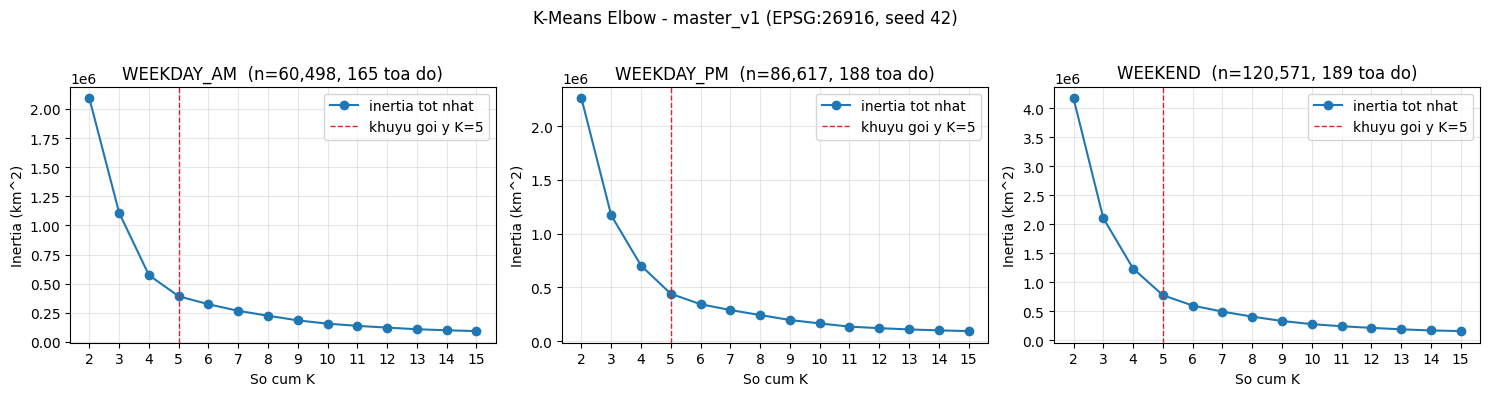

In [5]:
knees = {}
fig, axes = plt.subplots(1, len(SLICES), figsize=(5 * len(SLICES), 4), sharey=False)
for ax, s in zip(axes, SLICES):
    b = best.loc[s]
    knees[s] = knee_point(b.index, b.values)
    ax.plot(b.index, b.values / 1e6, "o-", color="#1f77b4", label="inertia tot nhat")
    ax.axvline(knees[s], color="#d62728", ls="--", lw=1, label=f"khuyu goi y K={knees[s]}")
    n = int(res.loc[res.time_slice == s, "n_points"].iloc[0]); u = int(res.loc[res.time_slice == s, "n_unique"].iloc[0])
    ax.set_title(f"{s}  (n={n:,}, {u} toa do)")
    ax.set_xlabel("So cum K"); ax.set_ylabel("Inertia (km^2)")
    ax.set_xticks(b.index); ax.grid(alpha=.3); ax.legend()
fig.suptitle(f"K-Means Elbow - {SAMPLE_ID} (EPSG:26916, seed {SEED})")
fig.tight_layout()

fig_path = resolve_path(cfg, "figures_dir") / f"kmeans_elbow_{SAMPLE_ID}.png"
csv_path = resolve_path(cfg, "run_log").parent / f"kmeans_elbow_{SAMPLE_ID}.csv"
fig_path.parent.mkdir(parents=True, exist_ok=True); csv_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_path, dpi=150)
res.to_csv(csv_path, index=False)
print("Khuyu goi y:", knees)
print("Da luu:", csv_path.relative_to(cfg["_root"]), "|", fig_path.relative_to(cfg["_root"]))

### Mức giảm inertia khi tăng K

Tỷ lệ giảm so với K-1. Khi tỷ lệ này nhỏ dần, tăng thêm cụm không còn cải thiện nhiều.

In [6]:
drop = (-best.groupby(level=0).pct_change() * 100).round(1).unstack(0)
drop

time_slice,WEEKDAY_AM,WEEKDAY_PM,WEEKEND
k,,,
2,NaN,NaN,NaN
3,47.0,48.2,49.6
4,48.3,39.9,41.3
5,31.7,37.3,37.3
6,17.5,22.0,23.0
7,17.5,15.9,17.5
8,15.8,16.1,17.7
9,17.8,18.9,18.4
10,15.4,16.3,16.6


## 3.2 Silhouette, DBI, CH theo K

Mỗi K fit theo cách `weighted` với n_init=50 (đề xuất ở 3.1, chưa sửa config), rồi gán nhãn lại cho từng chuyến và tính chỉ số bằng `src.evaluation.evaluate`:
- `silhouette`: tính trên từng chuyến, mẫu con tối đa 20.000 chuyến, seed 42. Càng cao càng tốt.
- `silhouette_unique`: tính trên các toạ độ duy nhất, không trọng số. Dùng để đối chiếu, vì nhiều chuyến trùng toạ độ kéo Silhouette lên.
- `davies_bouldin`: càng thấp càng tốt. `calinski_harabasz`: càng cao càng tốt.
- `smallest_share`: tỷ trọng của cụm nhỏ nhất. Quá nhỏ nghĩa là có cụm vụn.

In [7]:
from src.models.kmeans import scan_k, fit_weighted
K_RANGE = range(KM["k_min"], KM["k_max"] + 1)
scans = []
for s in SLICES:
    X = df.loc[df.time_slice == s, ["x_m", "y_m"]].to_numpy("float64")
    sc = scan_k(X, K_RANGE, init=KM["init"], n_init=N_INIT_HIGH, max_iter=KM["max_iter"], seed=SEED,
                silhouette_max_sample=cfg["evaluation"]["silhouette_max_sample"])
    scans.append(sc.assign(time_slice=s, sample_id=SAMPLE_ID, n_init=N_INIT_HIGH))
    print(f"{s:11s} xong ({sc.fit_sec.sum():.1f}s fit)")
scan = pd.concat(scans, ignore_index=True)
scan_path = resolve_path(cfg, "run_log").parent / f"kmeans_kscan_{SAMPLE_ID}.csv"
scan.to_csv(scan_path, index=False)
print("Da luu:", scan_path.relative_to(cfg["_root"]))

WEEKDAY_AM  xong (4.2s fit)
WEEKDAY_PM  xong (4.9s fit)
WEEKEND     xong (5.5s fit)
Da luu: outputs\metrics\kmeans_kscan_master_v1.csv


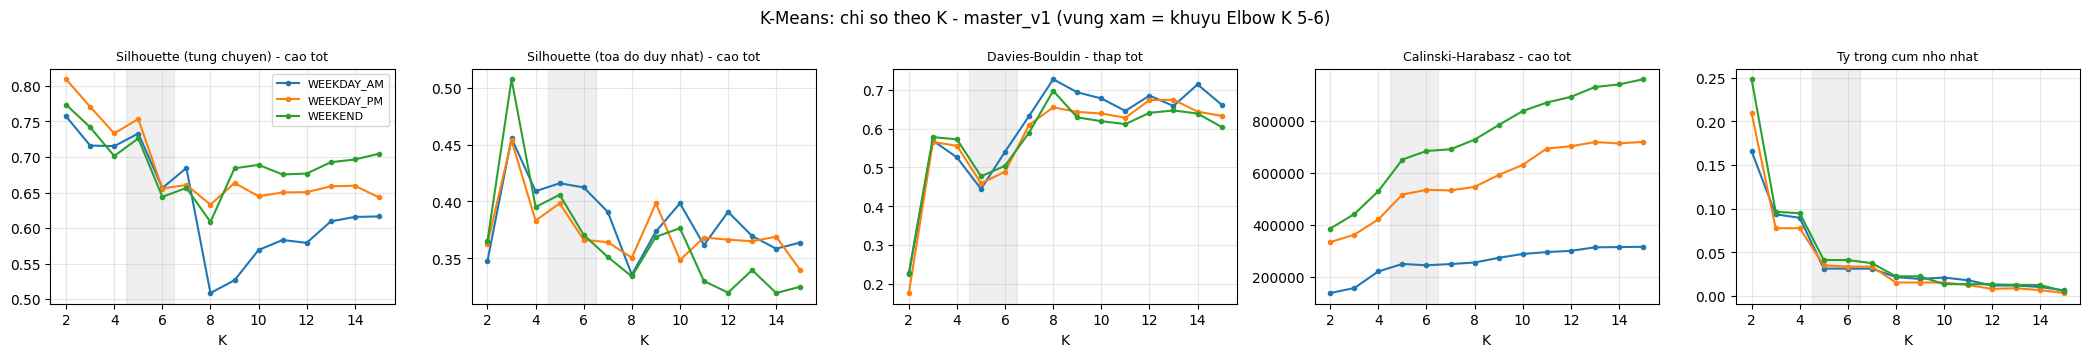

In [8]:
metrics = [("silhouette", "Silhouette (tung chuyen) - cao tot"), ("silhouette_unique", "Silhouette (toa do duy nhat) - cao tot"),
           ("davies_bouldin", "Davies-Bouldin - thap tot"), ("calinski_harabasz", "Calinski-Harabasz - cao tot"),
           ("smallest_share", "Ty trong cum nho nhat")]
fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.6))
for ax, (m, title) in zip(axes, metrics):
    for s in SLICES:
        d = scan[scan.time_slice == s]
        ax.plot(d.k, d[m], "o-", ms=3, label=s)
    ax.axvspan(4.5, 6.5, color="grey", alpha=.12)
    ax.set_title(title, fontsize=9); ax.set_xlabel("K"); ax.grid(alpha=.3); ax.set_xticks(list(K_RANGE)[::2])
axes[0].legend(fontsize=8)
fig.suptitle(f"K-Means: chi so theo K - {SAMPLE_ID} (vung xam = khuyu Elbow K 5-6)")
fig.tight_layout()
fig.savefig(resolve_path(cfg, "figures_dir") / f"kmeans_kscan_{SAMPLE_ID}.png", dpi=150)

### Bảng ứng viên K = 4..8

In [9]:
cand = scan[scan.k.between(4, 8)].set_index(["time_slice", "k"])[
    ["silhouette", "silhouette_unique", "davies_bouldin", "calinski_harabasz", "largest_share", "smallest_share"]]
print("K tot nhat theo tung chi so (K = 2..15):")
for s in SLICES:
    d = scan[scan.time_slice == s].set_index("k")
    print(f"  {s:11s} Silhouette max K={d.silhouette.idxmax()}, Sil.unique max K={d.silhouette_unique.idxmax()}, "
          f"DBI min K={d.davies_bouldin.idxmin()}, CH max K={d.calinski_harabasz.idxmax()}")
cand.round(3)

K tot nhat theo tung chi so (K = 2..15):
  WEEKDAY_AM  Silhouette max K=2, Sil.unique max K=3, DBI min K=2, CH max K=15
  WEEKDAY_PM  Silhouette max K=2, Sil.unique max K=3, DBI min K=2, CH max K=15
  WEEKEND     Silhouette max K=2, Sil.unique max K=3, DBI min K=2, CH max K=15


silhouette  silhouette_unique  davies_bouldin  \
time_slice k                                                  
WEEKDAY_AM 4       0.715              0.409           0.526   
           5       0.733              0.416           0.445   
           6       0.656              0.412           0.541   
           7       0.684              0.391           0.633   
           8       0.509              0.336           0.727   
WEEKDAY_PM 4       0.733              0.383           0.556   
           5       0.753              0.398           0.459   
           6       0.656              0.366           0.489   
           7       0.661              0.364           0.610   
           8       0.633              0.350           0.655   
WEEKEND    4       0.701              0.395           0.572   
           5       0.726              0.406           0.477   
           6       0.644              0.371           0.504   
           7       0.657              0.351           0.590   
           8       0.609              0.334           0.698   

              calinski_harabasz  largest_share  smallest_share  
time_slice k                                                    
WEEKDAY_AM 4         220323.451          0.622           0.090  
           5         249064.378          0.623           0.031  
           6         243929.462          0.576           0.031  
           7         248560.703          0.584           0.031  
           8         254599.824          0.336           0.022  
WEEKDAY_PM 4         420181.579          0.626           0.078  
           5         515724.080          0.625           0.035  
           6         533754.769          0.565           0.034  
           7         531604.319          0.538           0.034  
           8         545193.985          0.524           0.016  
WEEKEND    4         528629.399          0.526           0.095  
           5         650286.194          0.527           0.041  
           6         683050.435          0.455           0.041  
           7         689612.595          0.428           0.038  
           8         726720.791          0.285           0.023

### Bản đồ tĩnh các ứng viên K = 5 và K = 6

Mỗi chấm là một toạ độ centroid, kích thước chấm tỷ lệ với số chuyến, màu là cụm, dấu X là tâm cụm. Bản đồ tương tác (Folium) làm ở mục 3.3.

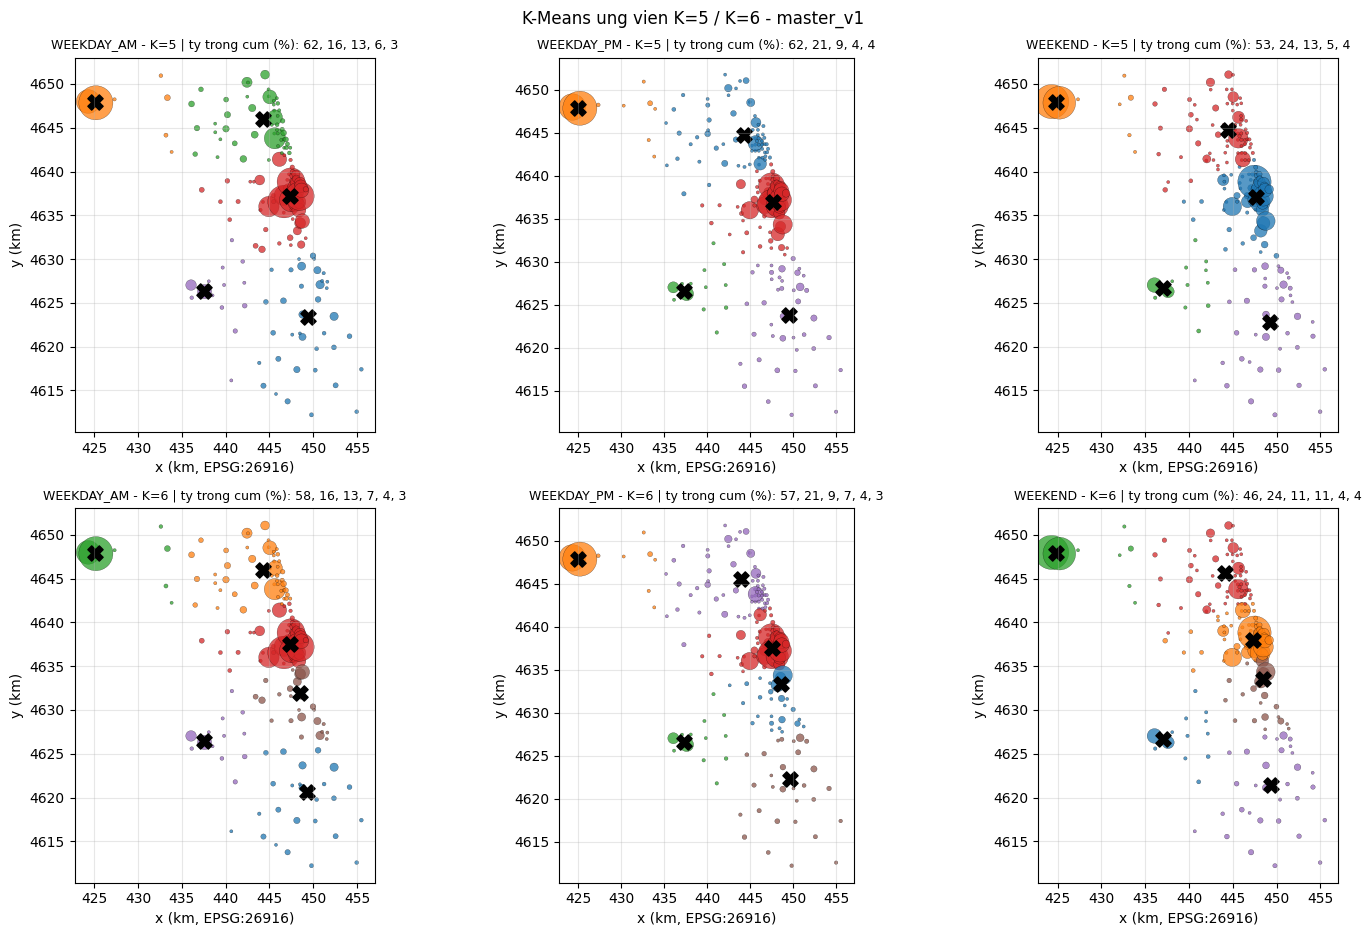

In [10]:
fig, axes = plt.subplots(2, len(SLICES), figsize=(5 * len(SLICES), 9.5))
for j, s in enumerate(SLICES):
    X = df.loc[df.time_slice == s, ["x_m", "y_m"]].to_numpy("float64")
    Xu, w, inv = aggregate_unique(X)
    for i, k in enumerate((5, 6)):
        lab, km = fit_weighted(X, k, init=KM["init"], n_init=N_INIT_HIGH, max_iter=KM["max_iter"], seed=SEED)
        ax = axes[i, j]
        ax.scatter(Xu[:, 0] / 1000, Xu[:, 1] / 1000, s=5 + 600 * w / w.max(), c=km.labels_, cmap="tab10",
                   vmin=0, vmax=9, alpha=.75, edgecolors="k", linewidths=.2)
        ax.scatter(km.cluster_centers_[:, 0] / 1000, km.cluster_centers_[:, 1] / 1000, marker="X", s=120, c="k")
        share = np.bincount(lab, minlength=k) / len(lab) * 100
        ax.set_title(f"{s} - K={k} | ty trong cum (%): " + ", ".join(f"{v:.0f}" for v in sorted(share, reverse=True)), fontsize=9)
        ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_xlabel("x (km, EPSG:26916)"); ax.set_ylabel("y (km)")
fig.suptitle(f"K-Means ung vien K=5 / K=6 - {SAMPLE_ID}")
fig.tight_layout()
fig.savefig(resolve_path(cfg, "figures_dir") / f"kmeans_candidates_{SAMPLE_ID}.png", dpi=130)

## 3.3 Fit K-Means với K đã chốt và bản đồ

- K lấy từ `config: kmeans.k_final` (chốt K = 5 ở mục 3.2). Dùng cách `weighted` với n_init=50.
- Mỗi lát cắt chạy qua `run_and_log`: đo runtime và RAM, tính chỉ số, lưu nhãn `outputs/labels/<run_id>.parquet`, ghi một dòng vào `outputs/metrics/run_log.csv`.
- Cụm được đánh số lại theo kích thước (cụm 0 là cụm lớn nhất) cho dễ đọc. Nhãn giữa các lát cắt không tương ứng với nhau, nên muốn ghép cụm giữa các lát cắt phải dựa vào toạ độ tâm (mục 5.1).
- **Mỗi lần chạy ô dưới sẽ ghi thêm 3 dòng vào run_log.csv**, đây là cách ghi có chủ đích (chỉ thêm, không sửa dòng cũ).

In [11]:
from src.evaluation import run_and_log
from src.evaluation.hotspots import relabel_by_size, cluster_table
K_FINAL = KM["k_final"]
params = {"k": K_FINAL, "init": KM["init"], "n_init": N_INIT_HIGH, "max_iter": KM["max_iter"],
          "random_state": SEED, "mode": "weighted"}

def fit_fn(X):
    lab, km = fit_weighted(X, K_FINAL, init=KM["init"], n_init=N_INIT_HIGH, max_iter=KM["max_iter"], seed=SEED)
    assert km.n_iter_ < KM["max_iter"], "K-Means chua hoi tu"
    return relabel_by_size(lab)

final = {}
for s in SLICES:
    part = df[df.time_slice == s].reset_index(drop=True)
    X = part[["x_m", "y_m"]].to_numpy("float64")
    row = run_and_log(cfg, "kmeans", fit_fn, X, part.trip_id.to_numpy(), member="M2", time_slice=s,
                      sample_id=SAMPLE_ID, params=params, note=f"du lieu M1 {SAMPLE_ID}; K={K_FINAL} chot o muc 5.1")
    lab = pd.read_parquet(resolve_path(cfg, "labels_dir") / f"{row['run_id']}.parquet")
    assert (lab.trip_id.values == part.trip_id.values).all()
    final[s] = (part, lab.label.to_numpy(), row)
    print(f"{row['run_id']}: {row['n_clusters']} cum, Silhouette {row['silhouette']:.3f}, DBI {row['davies_bouldin']:.3f}, "
          f"fit {row['runtime_fit_sec']:.3f}s, RAM them {row['mem_delta_mb']} MB")

kmeans_WEEKDAY_AM_20261121-171634: 5 cum, Silhouette 0.733, DBI 0.445, fit 0.286s, RAM them 3.3 MB
kmeans_WEEKDAY_PM_20261121-171641: 5 cum, Silhouette 0.753, DBI 0.459, fit 0.352s, RAM them 2.7 MB
kmeans_WEEKEND_20261121-171647: 5 cum, Silhouette 0.726, DBI 0.477, fit 0.390s, RAM them 3.7 MB


### Bảng cụm

Tâm cụm là trung bình toạ độ theo từng chuyến (tức là tâm có trọng số). `radius_rms_m` là độ phân tán quanh tâm. `top_community_area` là khu vực (community area) xuất hiện nhiều nhất trong cụm.

In [12]:
tabs = []
for s, (part, lab, row) in final.items():
    ct = cluster_table(part, lab, crs=cfg["project"]["crs"])
    tabs.append(ct.assign(time_slice=s, run_id=row["run_id"], sample_id=SAMPLE_ID))
clusters = pd.concat(tabs, ignore_index=True)
cl_path = resolve_path(cfg, "run_log").parent / f"kmeans_clusters_{SAMPLE_ID}.csv"
clusters.to_csv(cl_path, index=False)
print("Da luu:", cl_path.relative_to(cfg["_root"]))
show = clusters.assign(share_pct=(clusters.share * 100).round(1), radius_km=(clusters.radius_rms_m / 1000).round(2),
                       center=clusters.center_lat.round(4).astype(str) + ", " + clusters.center_lon.round(4).astype(str))
show[["time_slice", "cluster", "n_trips", "share_pct", "n_coords", "radius_km", "top_community_area", "center"]]

Da luu: outputs\metrics\kmeans_clusters_master_v1.csv


,time_slice,cluster,n_trips,share_pct,n_coords,radius_km,top_community_area,center
0,WEEKDAY_AM,0,37673,62.3,56,2.10,8,"41.8849, -87.6345"
1,WEEKDAY_AM,1,9695,16.0,7,1.34,76,"41.9795, -87.9042"
2,WEEKDAY_AM,2,7753,12.8,51,3.55,6,"41.9635, -87.673"
3,WEEKDAY_AM,3,3472,5.7,37,5.41,41,"41.7607, -87.6086"
4,WEEKDAY_AM,4,1905,3.1,14,2.06,56,"41.7869, -87.7511"
5,WEEKDAY_PM,0,54135,62.5,59,1.91,8,"41.8832, -87.6305"
6,WEEKDAY_PM,1,17937,20.7,9,1.00,76,"41.9795, -87.9058"
7,WEEKDAY_PM,2,7739,8.9,66,3.86,6,"41.9522, -87.6719"
8,WEEKDAY_PM,3,3757,4.3,41,5.25,41,"41.7642, -87.6077"
9,WEEKDAY_PM,4,3049,3.5,13,1.54,56,"41.7884, -87.755"


### Bản đồ tương tác

Mỗi lát cắt là một lớp, bật/tắt ở góc phải. File HTML cần Internet để tải nền bản đồ OpenStreetMap; khi thuyết trình thì dùng PNG dự phòng ở mục 3.2.

In [13]:
from src.visualization.maps import cluster_map
map_path = resolve_path(cfg, "maps_dir") / f"kmeans_map_{SAMPLE_ID}.html"
layers = {f"{s} (K={K_FINAL})": (part, lab, clusters[clusters.time_slice == s]) for s, (part, lab, row) in final.items()}
cluster_map(layers, map_path, title=f"K-Means K={K_FINAL} - {SAMPLE_ID}",
            note=f"Du lieu chinh thuc M1 ({SAMPLE_ID}, 4 tuan 17/04-14/05/2023).")
print("Da luu:", map_path.relative_to(cfg["_root"]), f"({map_path.stat().st_size / 1024:.0f} KB)")

Da luu: outputs\maps\kmeans_map_master_v1.html (411 KB)


### Các dòng vừa ghi vào run_log.csv

In [14]:
from src.evaluation import read_run_log
log = read_run_log(resolve_path(cfg, "run_log"))
ids = [row["run_id"] for _, _, row in final.values()]
log[log.run_id.isin(ids)][["run_id", "n_points", "n_clusters", "noise_ratio", "silhouette", "davies_bouldin",
                           "calinski_harabasz", "largest_share", "runtime_fit_sec", "mem_delta_mb", "machine"]]

,run_id,n_points,n_clusters,noise_ratio,silhouette,davies_bouldin,calinski_harabasz,largest_share,runtime_fit_sec,mem_delta_mb,machine
27,kmeans_WEEKDAY_AM_20261121-171634,60498,5,0.0,0.733076,0.444510,249064.378205,0.622715,0.2864,3.3,windows-16t-15GB
28,kmeans_WEEKDAY_PM_20261121-171641,86617,5,0.0,0.753465,0.459056,515724.080269,0.624993,0.3525,2.7,windows-16t-15GB
29,kmeans_WEEKEND_20261121-171647,120571,5,0.0,0.726121,0.477033,650286.194120,0.526619,0.3904,3.7,windows-16t-15GB
